# Optimización de hiperparámetros y comparación de modelos

**Curso:** Machine Learning · **Profesor:** Lihki Rubio Ortega
**Grupo:** Yuryen Rollo, Betzaida Ruiz

En el capítulo anterior ajustamos un SVR lineal que pronostica la velocidad del viento a 24 h con
`RMSE = 0.733 m/s` en 2025 y vimos que sus residuos conservan estructura no lineal. En este capítulo
comparamos siete modelos de regresión (KNN, Ridge, Lasso, árbol de decisión, Random Forest, XGBoost y SVR) y
cuatro estrategias de búsqueda de hiperparámetros (rejilla, búsqueda aleatoria, optimización bayesiana con
Optuna y algoritmo genético con DEAP), con validación cruzada anidada respetando el orden temporal. Además
medimos el costo computacional de cada modelo, revisamos los residuos, interpretamos el mejor modelo con SHAP y
LIME y comparamos los pronósticos con pruebas estadísticas para pronósticos (MCS, Giacomini-White,
Clark-West y Diebold-Mariano).

**Reproducibilidad.** Usamos el mismo conjunto de modelado causal de la sección 3 (26 predictoras de la sección
2.0, objetivo `y = vel(t + 24 h)`). Los experimentos están en la carpeta `e3/` (módulos con docstrings:
`datos.py`, `modelos.py`, `optimizadores.py`, `evaluacion.py`) y en `scripts/`, y este notebook solo lee sus
resultados. Desde la carpeta del repositorio:

```
python scripts/e3_preparar_datos.py    # conjunto de modelado (≈ 1 min)
python scripts/e3_experimentos.py      # 142 búsquedas con validación anidada (≈ 5 h en 6 procesos y una GPU)
python scripts/e3_computacional.py     # tiempos, memoria, variantes, paralelismo y perfilamiento (≈ 30 min)
python scripts/e3_semillas.py          # sensibilidad a la semilla (≈ 40 min)
```

Cada búsqueda guarda un JSON con su historial y sus predicciones, de modo que una corrida interrumpida se
reanuda sin repetir lo terminado. La semilla es `42` en todo el proyecto y las versiones están en
`requirements.txt` y al final de este capítulo. Usamos un procesador de 16 hilos, 32 GB de RAM y una GPU
NVIDIA RTX 4060 Ti para XGBoost.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scikit_posthocs as sp
import seaborn as sns
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.multitest import multipletests

sys.path.insert(0, str(Path.cwd()))
from e3 import SEED
from e3 import evaluacion as ev
from e3.datos import RESULTADOS, TRIMESTRES, cargar, pliegues_externos, submuestra
from e3.modelos import COMPLEJIDAD, ESPACIOS, MODELOS, construir

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
CORRIDAS = RESULTADOS / "corridas"
OPTIMIZADORES = ["Rejilla", "Aleatoria", "Bayesiana (Optuna)", "Genética (DEAP)"]
PLIEGUES = ["2024-T1", "2024-T2", "2024-T3", "2024-T4"]
COLORES = dict(zip(OPTIMIZADORES + ["Eliminación sucesiva"], sns.color_palette("tab10", 5)))

TR, TE, F = cargar()
X_tr, y_tr = TR[F].to_numpy(np.float32), TR.y.to_numpy()
X_te, y_te = TE[F].to_numpy(np.float32), TE.y.to_numpy()
pers_te = TE.vel_l0.to_numpy()                 # persistencia de 24 h: vel(t)
EXT = pliegues_externos(TR)


def archivo(modelo, optimizador, pliegue):
    return f"{modelo}__{optimizador}__{pliegue}".replace(" ", "_").replace("(", "").replace(")", "")


def leer(modelo, optimizador, pliegue):
    """Resultado (JSON) y predicciones (.npy) de una tarea de scripts/e3_experimentos.py."""
    n = archivo(modelo, optimizador, pliegue)
    return (json.loads((CORRIDAS / f"{n}.json").read_text(encoding="utf-8")), np.load(CORRIDAS / f"{n}.npy"))


print(f"Entrenamiento: {len(TR):,} filas ({TR.est.nunique()} estaciones) | prueba 2025: {len(TE):,} filas "
      f"({TE.est.nunique()} estaciones) | {len(F)} predictoras | semilla {SEED}")

Entrenamiento: 402,200 filas (57 estaciones) | prueba 2025: 213,972 filas (53 estaciones) | 26 predictoras | semilla 42


## 5.1 Diseño experimental

**Validación anidada temporal.** El bucle externo son los cuatro trimestres de 2024: para cada uno
entrenamos con todo lo anterior (ventana creciente, con las filas cuyo objetivo cae antes del inicio del
trimestre) y medimos en el trimestre. Dentro de cada pliegue externo, la búsqueda de hiperparámetros usa como
bucle interno los tres trimestres anteriores, de modo que nunca ve el trimestre con el que luego se la evalúa.
La configuración elegida se reentrena con todo el entrenamiento del pliegue y se mide en el trimestre
reservado: esos cuatro valores son los que reportamos como media ± desviación estándar. Para la evaluación final
repetimos la búsqueda con los cuatro trimestres de 2024 como bucle interno, reentrenamos con 2020–2024 y
predecimos 2025 una sola vez.

**Presupuesto igual para todos.** Cada optimizador dispone de `40` evaluaciones de la función objetivo, que es
el RMSE medio en los pliegues internos. Para acotar el costo, cada pliegue interno usa submuestras fijas de
`40 000` filas de ajuste y `10 000` de validación, las mismas para todas las configuraciones; así las
comparaciones entre configuraciones son pareadas. En total son 7 modelos × 4 optimizadores × 5 búsquedas (4
pliegues externos y la final) = `140` búsquedas, más dos de eliminación sucesiva.

**Optimizadores.**

| Optimizador | Detalle |
|---|---|
| Rejilla | Los niveles se reparten entre hiperparámetros según su importancia esperada hasta agotar las 40 evaluaciones; los de escala logarítmica se espacian en log |
| Aleatoria | Muestreo uniforme (log-uniforme en los rangos logarítmicos) |
| Bayesiana (Optuna) | Sustituto TPE multivariado, que modela por separado las densidades `l(x)` de las configuraciones buenas y `g(x)` de las malas; la adquisición es la mejora esperada, que equivale a maximizar `l(x)/g(x)`; 10 evaluaciones iniciales aleatorias |
| Genética (DEAP) | Esquema `(μ + λ)` con `μ = λ = 8` en el espacio normalizado `[0, 1]^d`; selección por torneo de tamaño 3, cruce SBX (`η = 15`, `p = 0.7`), mutación polinomial (`η = 20`, `p = 0.3`, probabilidad `1/d` por gen) y elitismo implícito en `(μ + λ)` |
| Eliminación sucesiva | Multi-fidelidad: 27 configuraciones aleatorias con 1/9 de las filas, las 9 mejores con 1/3 y las 3 mejores con todas (`η = 3`); el costo equivale a unas 9 evaluaciones completas. La aplicamos a Random Forest y XGBoost, los modelos más costosos |

**Modelos.** Todos los que dependen de la escala llevan `StandardScaler` dentro de un `Pipeline`, ajustado solo
con las filas de cada entrenamiento. Ridge y Lasso pueden transformar el objetivo con `log(1 + y)`. Para el SVR
con núcleo RBF usamos una aproximación de Nyström de 300 componentes seguida de un SVR lineal en el primal,
porque el núcleo completo es inviable con 400 mil filas (sección 5.3). Los rangos de búsqueda se fijaron por el
tamaño de los datos, antes de ver resultados:

In [2]:
tam = pd.DataFrame([{"pliegue externo": n, "entrenamiento": f"t_y < {TRIMESTRES[4 + k].date()}",
                     "filas de entrenamiento": len(tr), "filas de validación": len(va),
                     "estaciones en validación": TR.est.iloc[va].nunique()}
                    for k, (n, tr, va) in enumerate(EXT)])
tam.loc[4] = ["final (prueba 2025)", "t_y < 2025-01-01", len(TR), len(TE), TE.est.nunique()]
tam

,pliegue externo,entrenamiento,filas de entrenamiento,filas de validación,estaciones en validación
0,2024-T1,t_y < 2024-01-01,330276,5207,7
1,2024-T2,t_y < 2024-04-01,335536,6888,13
2,2024-T3,t_y < 2024-07-01,342517,16293,27
3,2024-T4,t_y < 2024-10-01,358949,43120,38
4,final (prueba 2025),t_y < 2025-01-01,402200,213972,53


In [3]:
def rango(h):
    if h[0] == "cat":
        return ", ".join(map(str, h[1]))
    return f"{h[1]:g} – {h[2]:g}" + (" (log)" if h[0].endswith("_log") else "")


pd.DataFrame([{"modelo": m, "hiperparámetro": k, "rango": rango(h)} for m, e in ESPACIOS.items()
              for k, h in e.items()]).set_index(["modelo", "hiperparámetro"])

rango
modelo            hiperparámetro                       
KNN               n_neighbors             5 – 300 (log)
                  weights             uniform, distance
                  p                                2, 1
Ridge             alpha             0.001 – 10000 (log)
                  log_y                     False, True
Lasso             alpha                 1e-05 – 1 (log)
                  log_y                     False, True
Árbol de decisión max_depth                      3 – 30
                  min_samples_leaf       5 – 2000 (log)
                  max_features                  0.3 – 1
Random Forest     min_samples_leaf        5 – 500 (log)
                  max_features                  0.2 – 1
                  max_depth                      5 – 25
                  n_estimators                 50 – 250
XGBoost           learning_rate        0.01 – 0.3 (log)
                  max_depth                      3 – 10
                  n_estimators               100 – 1000
                  min_child_weight        1 – 100 (log)
                  subsample                     0.5 – 1
                  colsample_bytree              0.5 – 1
                  reg_lambda           0.001 – 10 (log)
SVR               C                   0.0001 – 10 (log)
                  kernel                    lineal, rbf
                  gamma               0.001 – 0.3 (log)
                  epsilon                       0 – 0.5

Los trimestres de validación de 2024 tienen pocas filas al principio del año (`5 207` en el primero frente a
`43 120` en el último) porque la red tuvo menos estaciones con las cuatro variables en ese periodo. Por eso el RMSE
de los pliegues varía mucho y es más alto que en 2025: las estaciones de cada trimestre no son las mismas.

## 5.2 Resultados de la optimización

### Desempeño en el bucle externo

In [4]:
filas = []
for f in sorted(CORRIDAS.glob("*.json")):
    r = json.loads(f.read_text(encoding="utf-8"))
    filas.append({k: r.get(k) for k in ["modelo", "optimizador", "pliegue", "rmse", "mae", "r2", "mejor_rmse_interno",
                                         "evaluaciones", "segundos_busqueda", "segundos_ajuste_final"]}
                 | {"mejor_params": r["mejor_params"]})
T = pd.DataFrame(filas)
ext = T[T.pliegue != "final"]
fin = T[T.pliegue == "final"].set_index(["modelo", "optimizador"])

media = ext.pivot_table(index="modelo", columns="optimizador", values="rmse", aggfunc="mean")[OPTIMIZADORES]
desv = ext.pivot_table(index="modelo", columns="optimizador", values="rmse", aggfunc="std")[OPTIMIZADORES]
orden_modelos = media.min(axis=1).sort_values().index
(media.round(4).astype(str) + " ± " + desv.round(4).astype(str)).loc[orden_modelos]

optimizador,Rejilla,Aleatoria,Bayesiana (Optuna),Genética (DEAP)
modelo,,,,
XGBoost,0.8956 ± 0.0962,0.895 ± 0.0932,0.8976 ± 0.094,0.8983 ± 0.0946
Random Forest,0.8961 ± 0.0934,0.8971 ± 0.0945,0.8961 ± 0.0931,0.8974 ± 0.0951
SVR,0.8999 ± 0.0944,0.9083 ± 0.0932,0.9113 ± 0.0967,0.9006 ± 0.0935
Ridge,0.9103 ± 0.0967,0.9103 ± 0.0967,0.9103 ± 0.0967,0.9103 ± 0.0967
Lasso,0.9104 ± 0.0967,0.9103 ± 0.0967,0.9104 ± 0.0967,0.9104 ± 0.0967
KNN,0.9223 ± 0.0977,0.9239 ± 0.0985,0.9229 ± 0.098,0.9238 ± 0.0981
Árbol de decisión,0.9407 ± 0.095,0.9343 ± 0.0978,0.9402 ± 0.0963,0.9348 ± 0.0984


In [5]:
# optimizador elegido para cada modelo: el de menor RMSE medio en el bucle externo (2025 no interviene)
elegido = media.idxmin(axis=1)
resumen = pd.DataFrame({
    "optimizador elegido": elegido,
    "RMSE externo (media ± d.e.)": [f"{media.loc[m, o]:.4f} ± {desv.loc[m, o]:.4f}" for m, o in elegido.items()],
    "RMSE 2025": [fin.loc[(m, o), "rmse"] for m, o in elegido.items()],
    "MAE 2025": [fin.loc[(m, o), "mae"] for m, o in elegido.items()],
    "R² 2025": [fin.loc[(m, o), "r2"] for m, o in elegido.items()],
    "configuración final": [fin.loc[(m, o), "mejor_params"] for m, o in elegido.items()]}).loc[orden_modelos]
resumen.round(4)

,optimizador elegido,RMSE externo (media ± d.e.),RMSE 2025,MAE 2025,R² 2025,configuración final
modelo,,,,,,
XGBoost,Aleatoria,0.8950 ± 0.0932,0.7268,0.5123,0.7413,"{'learning_rate': 0.011650335455725839, 'max_depth': 6, 'n_estimators': 993, 'min_child_weight': 60.72318357191729, ..."
Random Forest,Bayesiana (Optuna),0.8961 ± 0.0931,0.7227,0.5110,0.7442,"{'min_samples_leaf': 5, 'max_features': 0.23785127699240788, 'max_depth': 21, 'n_estimators': 232}"
SVR,Rejilla,0.8999 ± 0.0944,0.7311,0.5179,0.7382,"{'C': 9.999999999999993, 'kernel': 'rbf', 'gamma': 0.0010000000000000002, 'epsilon': 0.0}"
Ridge,Aleatoria,0.9103 ± 0.0967,0.7330,0.5194,0.7369,"{'alpha': 79.77296129247246, 'log_y': False}"
Lasso,Aleatoria,0.9103 ± 0.0967,0.7330,0.5194,0.7369,"{'alpha': 1.4259003408850091e-05, 'log_y': False}"
KNN,Rejilla,0.9223 ± 0.0977,0.7349,0.5134,0.7355,"{'n_neighbors': 49, 'weights': 'distance', 'p': 1}"
Árbol de decisión,Aleatoria,0.9343 ± 0.0978,0.7607,0.5370,0.7166,"{'max_depth': 24, 'min_samples_leaf': 224, 'max_features': 0.6875055804605971}"


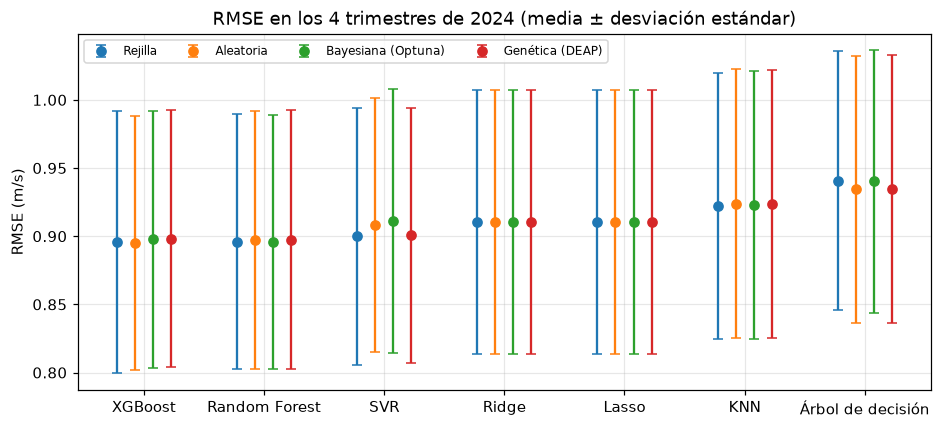

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for i, o in enumerate(OPTIMIZADORES):
    d = ext[ext.optimizador == o].set_index("modelo").loc[orden_modelos]
    g = d.groupby(level=0, sort=False).rmse
    ax.errorbar(np.arange(len(orden_modelos)) + (i - 1.5) * .15, g.mean(), g.std(), fmt="o", capsize=3,
                color=COLORES[o], label=o)
ax.set_xticks(range(len(orden_modelos)), orden_modelos)
ax.set(ylabel="RMSE (m/s)", title="RMSE en los 4 trimestres de 2024 (media ± desviación estándar)")
ax.legend(ncol=4, fontsize=8)
plt.show()

Los cuatro optimizadores llegan a errores muy parecidos en cada modelo. La desviación estándar entre
trimestres (`≈ 0.09 m/s`) es unas 20 veces mayor que la diferencia entre optimizadores dentro de un mismo modelo,
lo que confirma que el trimestre (y su conjunto de estaciones) pesa más que la estrategia de búsqueda. Para cada
modelo elegimos el optimizador con menor RMSE medio en el bucle externo, sin mirar 2025. Con esa regla el mejor
modelo es **XGBoost con búsqueda aleatoria** (`0.8950 ± 0.0932`), seguido de cerca por Random Forest con Optuna
(`0.8961 ± 0.0931`).

### Tiempo de cómputo y número de evaluaciones

In [7]:
costo = T[T.optimizador != "Eliminación sucesiva"].groupby(["modelo", "optimizador"]).agg(
    evaluaciones=("evaluaciones", "mean"), minutos_busqueda=("segundos_busqueda", lambda s: s.sum() / 60),
    s_por_evaluacion=("segundos_busqueda", lambda s: s.sum() / 200))
costo.unstack().loc[orden_modelos, ["minutos_busqueda", "s_por_evaluacion"]].round(2)

minutos_busqueda                                             \
optimizador              Aleatoria Bayesiana (Optuna) Genética (DEAP) Rejilla   
modelo                                                                          
XGBoost                     108.06             105.59           37.99  110.39   
Random Forest               119.03              97.64           92.77   89.67   
SVR                          12.15              12.40           25.30   10.35   
Ridge                         0.37               0.36            0.32    0.38   
Lasso                         0.59               1.02            1.18    0.53   
KNN                          18.24              20.61           19.94   18.95   
Árbol de decisión             2.95               2.90            3.04    2.56   

                  s_por_evaluacion                                             
optimizador              Aleatoria Bayesiana (Optuna) Genética (DEAP) Rejilla  
modelo                                                                         
XGBoost                      32.42              31.68           11.40   33.12  
Random Forest                35.71              29.29           27.83   26.90  
SVR                           3.65               3.72            7.59    3.11  
Ridge                         0.11               0.11            0.10    0.11  
Lasso                         0.18               0.31            0.35    0.16  
KNN                           5.47               6.18            5.98    5.68  
Árbol de decisión             0.89               0.87            0.91    0.77

In [8]:
# Friedman entre optimizadores: bloques = modelo × pliegue externo (28 bloques)
bloq_opt = ext.pivot_table(index=["modelo", "pliegue"], columns="optimizador", values="rmse")[OPTIMIZADORES]
fr_opt = ev.friedman_nemenyi(bloq_opt)
print(f"Friedman entre optimizadores: χ² = {fr_opt['chi2']:.2f}, gl = {fr_opt['gl']}, p = {fr_opt['p_valor']:.3f}, "
      f"N = {fr_opt['N']} bloques, CD (Nemenyi, α = 0.05) = {fr_opt['CD']:.2f}")
print("Rangos promedio:", fr_opt["rangos"].round(2).to_dict())

Friedman entre optimizadores: χ² = 1.47, gl = 3, p = 0.690, N = 28 bloques, CD (Nemenyi, α = 0.05) = 0.89
Rangos promedio: {'Rejilla': 2.34, 'Aleatoria': 2.38, 'Bayesiana (Optuna)': 2.62, 'Genética (DEAP)': 2.66}


Los modelos lineales resuelven una búsqueda completa en segundos, mientras que XGBoost y Random Forest
necesitan entre 1.5 y 2 horas de cómputo por optimizador para las cinco búsquedas. El algoritmo genético fue
tres veces más barato en XGBoost (`11.4 s` por evaluación frente a `≈ 32 s`): su población convergió hacia
configuraciones con menos árboles (`326` en promedio frente a `≈ 550`) y menor profundidad (`4.9` frente a
`6.5`), que son más baratas sin ser peores. La prueba de Friedman con los 28 bloques modelo × trimestre no
encuentra diferencias entre optimizadores (`χ² = 1.47`, `p = 0.69`): los rangos promedio van de `2.34` (rejilla) a
`2.66` (genético), todos dentro de la diferencia crítica de Nemenyi (`CD = 0.89`).

### Curvas de convergencia (*anytime*)

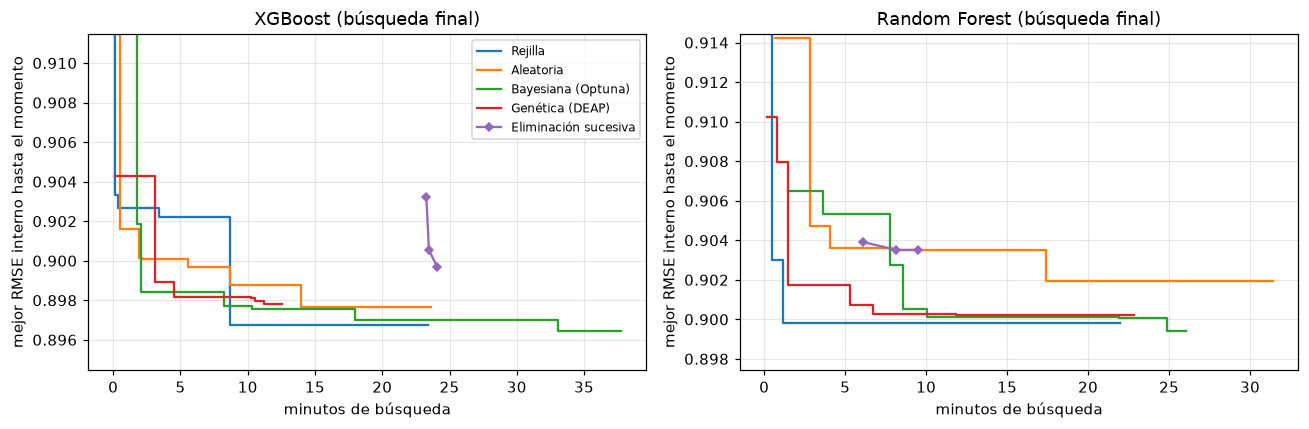

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, m in zip(axs, ["XGBoost", "Random Forest"]):
    for o in OPTIMIZADORES + ["Eliminación sucesiva"]:
        r, _ = leer(m, o, "final")
        h = pd.DataFrame(r["historial"])
        if o == "Eliminación sucesiva":
            h = h[h.fraccion == 1]          # solo las evaluaciones con fidelidad completa son comparables
            ax.plot(h.segundos_acumulados / 60, h.rmse.cummin(), "D-", color=COLORES[o], label=o, ms=4)
        else:
            ax.step(h.segundos_acumulados / 60, h.rmse.cummin(), where="post", color=COLORES[o], label=o)
    mejor = min(leer(m, o, "final")[0]["mejor_rmse_interno"] for o in OPTIMIZADORES)
    ax.set(xlabel="minutos de búsqueda", ylabel="mejor RMSE interno hasta el momento", title=f"{m} (búsqueda final)",
           ylim=(mejor - .002, mejor + .015))
axs[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

Las curvas muestran el mejor RMSE interno alcanzado en función del tiempo de búsqueda. En XGBoost todas
las estrategias bajan de `0.905` en los dos primeros minutos y después mejoran en milésimas: Optuna llega a `0.8985`
a los 2 minutos y es la que termina más abajo (`0.8965`), mientras que la rejilla da su mejor salto a los 9. En Random
Forest la rejilla llega a `0.900` en un minuto y la búsqueda aleatoria se queda en `0.902` después de 31 minutos.
Con 40 evaluaciones, la ventaja de la optimización bayesiana sobre la aleatoria aparece al final de la búsqueda
(es la que termina con el menor RMSE interno en ambos modelos), pero es pequeña. Los tiempos son de reloj y
incluyen la competencia con los otros procesos que corrían en paralelo.

### Eliminación sucesiva frente a búsqueda aleatoria con el mismo costo

In [10]:
filas = []
for m in ["Random Forest", "XGBoost"]:
    sh, _ = leer(m, "Eliminación sucesiva", "final")
    al, _ = leer(m, "Aleatoria", "final")
    h = pd.DataFrame(al["historial"])
    mismo_t = h[h.segundos_acumulados <= sh["segundos_busqueda"]]
    filas.append({"modelo": m, "SH: RMSE interno": sh["mejor_rmse_interno"],
                  "SH: evaluaciones equivalentes": sh["evaluaciones_equivalentes"],
                  "SH: minutos": sh["segundos_busqueda"] / 60, "SH: RMSE 2025": sh["rmse"],
                  "aleatoria, 9 evaluaciones": h.rmse.iloc[:9].min(),
                  "aleatoria, mismo tiempo": mismo_t.rmse.min() if len(mismo_t) else np.nan,
                  "evaluaciones en ese tiempo": len(mismo_t),
                  "aleatoria, 40 evaluaciones": al["mejor_rmse_interno"],
                  "aleatoria: minutos (40)": al["segundos_busqueda"] / 60, "aleatoria: RMSE 2025": al["rmse"]})
pd.DataFrame(filas).set_index("modelo").T.round(4)

modelo,Random Forest,XGBoost
SH: RMSE interno,0.9035,0.8997
SH: evaluaciones equivalentes,9.0000,9.0000
SH: minutos,9.4919,24.0788
SH: RMSE 2025,0.7243,0.7295
"aleatoria, 9 evaluaciones",0.9035,0.9001
"aleatoria, mismo tiempo",0.9035,0.8976
evaluaciones en ese tiempo,10.0000,40.0000
"aleatoria, 40 evaluaciones",0.9020,0.8976
aleatoria: minutos (40),31.3922,23.6281
aleatoria: RMSE 2025,0.7236,0.7268


La eliminación sucesiva no ahorró trabajo en este problema. En Random Forest gastó `9.5` minutos y llegó
al mismo RMSE interno (`0.9035`) que la búsqueda aleatoria en el mismo tiempo, y en XGBoost la búsqueda aleatoria
encontró una configuración mejor (`0.8976` frente a `0.8997`) en menos tiempo. La razón es que con 1/9 de las filas
(unas 4 400) el orden de las configuraciones no se mantiene con todos los datos: en XGBoost, la mejor combinación de
número de árboles y tasa de aprendizaje depende del tamaño de la muestra, así que la primera ronda descarta
configuraciones que habrían sido buenas con más filas. La multi-fidelidad conviene cuando la fidelidad baja
ordena bien las configuraciones, y aquí no ocurre.

### Diversidad de la población en el algoritmo genético

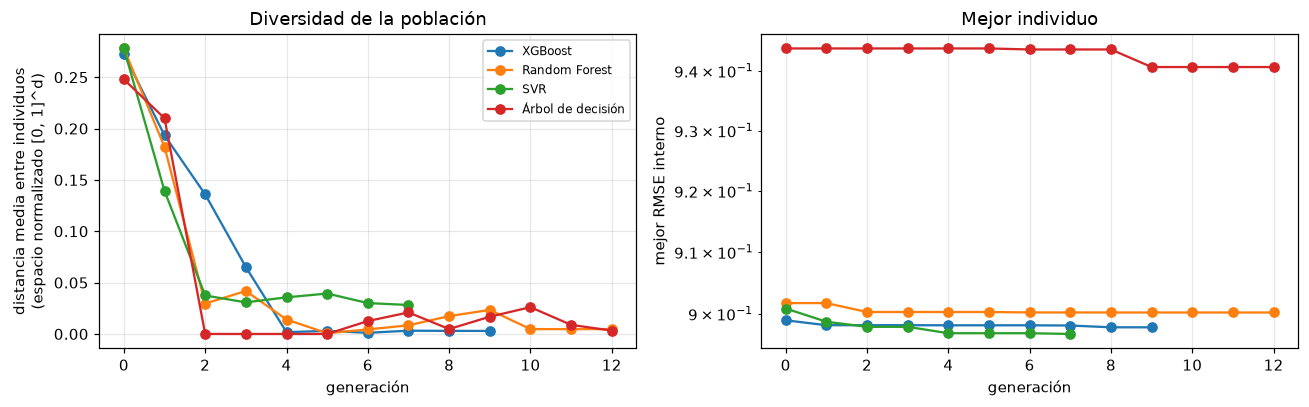

Operadores: {'seleccion': 'torneo (tamaño 3)', 'cruce': 'SBX acotado, η = 15, p = 0.7', 'mutacion': 'polinomial acotada, η = 20, p = 0.3, 1/d por gen', 'elitismo': '(μ + λ)', 'mu': 8, 'lambda': 8}


In [11]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for m, c in [("XGBoost", "C0"), ("Random Forest", "C1"), ("SVR", "C2"), ("Árbol de decisión", "C3")]:
    r, _ = leer(m, "Genética (DEAP)", "final")
    d = pd.DataFrame(r["diversidad"])
    axs[0].plot(d.generacion, d.diversidad, "o-", color=c, label=m)
    axs[1].plot(d.generacion, d.mejor, "o-", color=c, label=m)
axs[0].set(xlabel="generación", ylabel="distancia media entre individuos\n(espacio normalizado [0, 1]^d)",
           title="Diversidad de la población")
axs[1].set(xlabel="generación", ylabel="mejor RMSE interno", title="Mejor individuo", yscale="log")
axs[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Operadores:", leer("XGBoost", "Genética (DEAP)", "final")[0]["operadores"])

La diversidad (distancia media entre individuos en el espacio normalizado) cae de `≈ 0.27` a casi cero entre
la segunda y la cuarta generación: con una población de 8, la presión de selección del torneo y el elitismo
`(μ + λ)` concentran rápidamente la población alrededor del mejor individuo, y la mutación polinomial apenas la
separa de nuevo (solo el SVR conserva algo de diversidad). El mejor individuo casi no mejora después de la
generación 2. Con 40 evaluaciones la búsqueda genética explota mucho más de lo que explora; una población mayor o
una mutación más fuerte la harían más exploratoria, a costa de más evaluaciones. Las generaciones son más de 4
porque las configuraciones repetidas salen de la caché y no consumen presupuesto.

### Sensibilidad a la semilla

In [12]:
sm = pd.read_csv(RESULTADOS / "semillas" / "semilla_modelo.csv")
sm.groupby("modelo").rmse.agg(["mean", "std", "min", "max"]).round(4)

,mean,std,min,max
modelo,,,,
Random Forest,0.7232,0.0002,0.7229,0.7235
SVR,0.7317,0.0006,0.7312,0.7325
XGBoost,0.7266,0.0003,0.7262,0.7271
Árbol de decisión,0.7567,0.0012,0.7555,0.7583


In [13]:
ruta_sb = RESULTADOS / "semillas" / "semilla_busqueda.csv"
if ruta_sb.exists():
    sb = pd.read_csv(ruta_sb)
    base = pd.DataFrame([{"optimizador": o, "semilla_busqueda": SEED,
                          "mejor_rmse_interno": leer("XGBoost", o, "final")[0]["mejor_rmse_interno"],
                          "rmse_2025": leer("XGBoost", o, "final")[0]["rmse"]}
                         for o in ["Aleatoria", "Bayesiana (Optuna)", "Genética (DEAP)"]])
    sb = pd.concat([base, sb[base.columns]], ignore_index=True)
    display(sb.groupby("optimizador")[["mejor_rmse_interno", "rmse_2025"]].agg(["mean", "std", "min", "max"]).round(4))

mejor_rmse_interno                         rmse_2025  \
                                 mean     std     min     max      mean   
optimizador                                                               
Aleatoria                      0.8977  0.0008  0.8970  0.8988    0.7266   
Bayesiana (Optuna)             0.8969  0.0003  0.8965  0.8971    0.7245   
Genética (DEAP)                0.8979  0.0015  0.8966  0.9000    0.7263   

                                            
                       std     min     max  
optimizador                                 
Aleatoria           0.0006  0.7260  0.7273  
Bayesiana (Optuna)  0.0011  0.7234  0.7261  
Genética (DEAP)     0.0030  0.7235  0.7301

La semilla del modelo cambia el RMSE en 2025 en menos de una milésima en Random Forest y XGBoost
(desviación de `0.0002` y `0.0003`), y algo más en el árbol (`0.0012`). La semilla del optimizador pesa más: al
repetir la búsqueda final de XGBoost con tres semillas adicionales, el RMSE en 2025 varía con una desviación de
`0.0006` (aleatoria), `0.0011` (Optuna) y `0.0030` (genético). Esa variabilidad es del mismo orden que las
diferencias entre optimizadores de la tabla anterior, otra señal de que ninguno es claramente superior. La
búsqueda bayesiana es la más estable en el RMSE interno (`0.8969 ± 0.0003`).

## 5.3 Optimización computacional

### Complejidad teórica y tiempos medidos

In [14]:
esc = pd.read_csv(RESULTADOS / "computacional" / "escalamiento.csv")
pend = esc[esc.n >= 40000].groupby("modelo").apply(
    lambda d: pd.Series({"exponente ajuste": np.polyfit(np.log(d.n), np.log(d.ajuste_s), 1)[0],
                         "s ajuste (320 mil)": d.ajuste_s.iloc[-1], "s predicción (10 mil)": d.prediccion_s.iloc[-1]}))
pend["complejidad del ajuste"] = [COMPLEJIDAD[m][0] for m in pend.index]
pend["complejidad de la predicción"] = [COMPLEJIDAD[m][1] for m in pend.index]
mem = pd.read_csv(RESULTADOS / "computacional" / "memoria.csv").set_index("modelo")
pend["memoria pico (MB, 160 mil filas)"] = mem.memoria_MB
pend.loc[MODELOS].round(3)

,exponente ajuste,s ajuste (320 mil),s predicción (10 mil),complejidad del ajuste,complejidad de la predicción,"memoria pico (MB, 160 mil filas)"
modelo,,,,,,
KNN,1.203,1.258,39.407,O(1) (solo guarda los datos; O(n log n) si construye un KD-Tree),O(n·p) por consulta con búsqueda exhaustiva; ≈O(p·log n) con KD-Tree en dimensión baja,69.348
Ridge,1.076,0.164,0.001,O(n·p² + p³) (ecuaciones normales con Cholesky),O(p),48.879
Lasso,1.028,0.202,0.001,O(n·p) por iteración de descenso por coordenadas,O(p),49.027
Árbol de decisión,1.162,4.765,0.001,O(p·n·log n),O(d),18.473
Random Forest,1.186,62.238,0.033,"O(T·p'·n·log n), p' = max_features·p",O(T·d),66.906
XGBoost,0.175,1.736,0.022,O(T·p·n) con histogramas (método hist); O(T·p·n·log n) con el método exacto,O(T·d),198.090
SVR,1.036,0.530,0.001,O(n·p) por iteración (lineal); O(n·m² + n·m·p) con Nyström,O(p) lineal; O(m·p) con Nyström,143.730


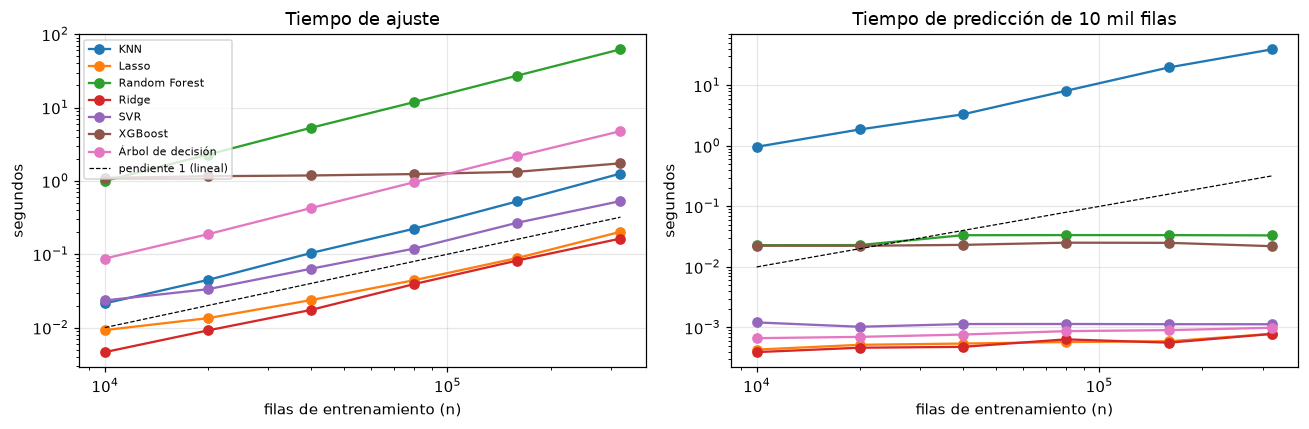

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for m, d in esc.groupby("modelo"):
    axs[0].loglog(d.n, d.ajuste_s, "o-", label=m)
    axs[1].loglog(d.n, d.prediccion_s, "o-", label=m)
nn = np.array([1e4, 3.2e5])
for ax in axs:
    ax.loglog(nn, 1e-2 * nn / nn[0], "k--", lw=.8, label="pendiente 1 (lineal)")
axs[0].set(xlabel="filas de entrenamiento (n)", ylabel="segundos", title="Tiempo de ajuste")
axs[1].set(xlabel="filas de entrenamiento (n)", ylabel="segundos", title="Tiempo de predicción de 10 mil filas")
axs[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

El exponente empírico es la pendiente de `log(tiempo)` frente a `log(n)` entre 40 mil y 320 mil filas. Ridge,
Lasso y el SVR lineal crecen de forma lineal (`1.03–1.08`), como predice `O(n·p)` con `p` fijo. El árbol, Random
Forest y KNN con KD-Tree tienen exponentes de `1.16–1.20`, coherentes con `O(n log n)`. XGBoost en GPU casi no
cambia (`0.18`): con estos tamaños domina el costo fijo de transferir los datos y lanzar los núcleos de la GPU, no
el número de filas. En la predicción, KNN es la excepción: pronosticar 10 mil filas con 320 mil de referencia
tarda `39 s`, porque cada consulta recorre el árbol en 26 dimensiones, donde la estructura pierde su ventaja.

### Variantes estándar frente a optimizadas

In [16]:
var = pd.read_csv(RESULTADOS / "computacional" / "variantes.csv")
var.set_index(["modelo", "variante"]).round(4)

n  ajuste_s  prediccion_s  \
modelo  variante                                                           
KNN     brute                             160000    0.1650        5.4806   
        kd_tree                           160000    2.7849       53.7945   
        ball_tree                         160000    0.6002       33.1273   
Ridge   cholesky                          320000    0.2045        0.0010   
        saga                              320000    2.2158        0.0008   
        sparse_cg                         320000    0.2344        0.0008   
Lasso   descenso por coordenadas          320000    0.3093        0.0009   
        SGD (L1)                          320000    0.7804        0.0009   
XGBoost exact (CPU)                       160000   33.4348        0.0178   
        hist (CPU)                        160000    4.3077        0.0123   
        hist (GPU)                        160000    5.5666        0.0683   
SVR     núcleo RBF completo (n = 2500)      2500    0.2508        0.3234   
        Nyström 300 + primal (n = 2500)     2500    0.1107        0.0129   
        núcleo RBF completo (n = 5000)      5000    0.9473        0.6385   
        Nyström 300 + primal (n = 5000)     5000    0.1590        0.0134   
        núcleo RBF completo (n = 10000)    10000    3.7393        1.2163   
        Nyström 300 + primal (n = 10000)   10000    0.3669        0.0115   
        núcleo RBF completo (n = 20000)    20000   14.6771        2.4684   
        Nyström 300 + primal (n = 20000)   20000    0.8656        0.0083   
        lineal primal (LinearSVR)         320000    0.8179        0.0015   
        lineal SGD                        320000    0.6711        0.0008   

                                            rmse  
modelo  variante                                  
KNN     brute                             0.6545  
        kd_tree                           0.6545  
        ball_tree                         0.6545  
Ridge   cholesky                          0.6560  
        saga                              0.6560  
        sparse_cg                         0.6561  
Lasso   descenso por coordenadas          0.6565  
        SGD (L1)                          0.6554  
XGBoost exact (CPU)                       0.6456  
        hist (CPU)                        0.6466  
        hist (GPU)                        0.6466  
SVR     núcleo RBF completo (n = 2500)    0.6201  
        Nyström 300 + primal (n = 2500)   0.6458  
        núcleo RBF completo (n = 5000)    0.6274  
        Nyström 300 + primal (n = 5000)   0.6533  
        núcleo RBF completo (n = 10000)   0.6108  
        Nyström 300 + primal (n = 10000)  0.6248  
        núcleo RBF completo (n = 20000)   0.6235  
        Nyström 300 + primal (n = 20000)  0.6246  
        lineal primal (LinearSVR)         0.6560  
        lineal SGD                        0.6573

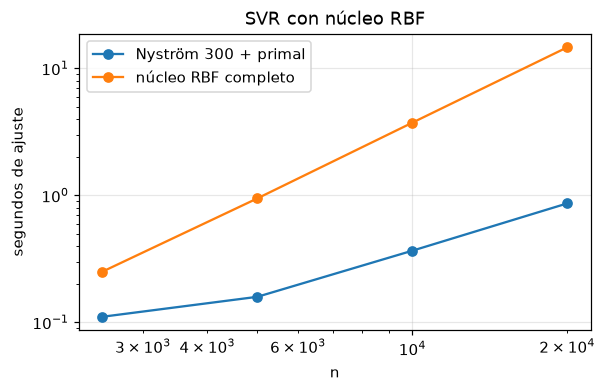

Nyström 300 + primal: exponente empírico 1.01
núcleo RBF completo: exponente empírico 1.96


In [17]:
fig, ax = plt.subplots(figsize=(6, 3.5))
s = var[var.modelo == "SVR"].copy()
s = s[s.variante.str.contains("n =")]
s["tipo"] = np.where(s.variante.str.startswith("núcleo"), "núcleo RBF completo", "Nyström 300 + primal")
for t, d in s.groupby("tipo"):
    ax.loglog(d.n, d.ajuste_s, "o-", label=t)
ax.set(xlabel="n", ylabel="segundos de ajuste", title="SVR con núcleo RBF")
ax.legend()
plt.show()
for t, d in s.groupby("tipo"):
    print(f"{t}: exponente empírico {np.polyfit(np.log(d.n), np.log(d.ajuste_s), 1)[0]:.2f}")

Las variantes optimizadas dan el mismo resultado en mucho menos tiempo:

- **KNN:** la búsqueda exhaustiva (`brute`) predice 10 veces más rápido que el KD-Tree (`5.5 s` frente a `53.8 s`),
  con resultados idénticos. Con 26 predictoras los árboles de búsqueda podan poco (maldición de la dimensión) y
  la búsqueda exhaustiva aprovecha mejor las operaciones vectorizadas. Por eso los experimentos usan
  `algorithm="auto"`, que elige `brute`.
- **Ridge:** las ecuaciones normales con Cholesky son 11 veces más rápidas que SAGA (`0.20 s` frente a `2.2 s`).
- **Lasso:** el descenso por coordenadas es 2.5 veces más rápido que SGD con penalización L1.
- **XGBoost:** el método por histogramas es 7.8 veces más rápido que el exacto con casi el mismo error. Con 160
  mil filas y 300 árboles, la GPU (`5.6 s`) no supera a la CPU con 16 hilos (`4.3 s`), pero la usamos porque deja
  libres los núcleos de la CPU para los otros procesos que corrían en paralelo.
- **SVR con núcleo RBF:** el núcleo completo crece con exponente `1.96` (cuadrático, como se espera de construir
  la matriz de núcleo) y Nyström con `1.01`. Con 20 mil filas el núcleo completo tarda `14.7 s` y Nyström `0.87 s`,
  con un RMSE casi igual (`0.6235` frente a `0.6246`). Extrapolando, el núcleo completo con 400 mil filas
  tardaría horas por ajuste.

### Parada temprana, paralelismo y perfilamiento

In [18]:
display(pd.read_csv(RESULTADOS / "computacional" / "parada_temprana.csv").round(4))
par = pd.read_csv(RESULTADOS / "computacional" / "paralelismo.csv")
rf = par[par.experimento == "Random Forest n_jobs"].copy()
rf["aceleración"] = rf.segundos.iloc[0] / rf.segundos
rf["eficiencia"] = rf["aceleración"] / rf.configuracion.astype(int)
display(rf.round(2))
display(par[par.experimento != "Random Forest n_jobs"].round(2))

,variante,ajuste_s,arboles,rmse_2024T4
0,1500 árboles fijos,26.7447,1500,0.7977
1,parada temprana (50 rondas),5.4560,217,0.7668


,experimento,configuracion,segundos,aceleración,eficiencia
0,Random Forest n_jobs,1,79.96,1.00,1.00
1,Random Forest n_jobs,2,40.33,1.98,0.99
2,Random Forest n_jobs,4,22.15,3.61,0.90
3,Random Forest n_jobs,8,12.43,6.43,0.80
4,Random Forest n_jobs,16,9.18,8.71,0.54


,experimento,configuracion,segundos
5,6 ajustes de árbol,en serie,4.88
6,6 ajustes de árbol,joblib loky,3.93
7,6 ajustes de árbol,joblib threading,1.07


In [19]:
perfil = (RESULTADOS / "computacional" / "perfil.txt").read_text(encoding="utf-8")
for bloque in perfil.split("=====")[1:]:
    print(bloque[:1800].rstrip(), "\n")

 KNN 


         20368 function calls (20284 primitive calls) in 11.592 seconds

   Ordered by: cumulative time
   List reduced from 522 to 12 due to restriction <12>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        3    0.000    0.000   11.138    3.713 C:\Users\USER\miniconda3\envs\ml_env\Lib\site-packages\sklearn\pipeline.py:746(predict)
        3    0.005    0.002   11.134    3.711 C:\Users\USER\miniconda3\envs\ml_env\Lib\site-packages\sklearn\neighbors\_regression.py:229(predict)
        3    0.000    0.000   11.128    3.709 C:\Users\USER\miniconda3\envs\ml_env\Lib\site-packages\sklearn\neighbors\_base.py:756(kneighbors)
        3    0.000    0.000   11.120    3.707 C:\Users\USER\miniconda3\envs\ml_env\Lib\site-packages\sklearn\utils\parallel.py:54(__call__)
        3    0.000    0.000   11.120    3.707 C:\Users\USER\miniconda3\envs\ml_env\Lib\site-packages\joblib\parallel.py:1969(__call__)
       18    0.000    0.000   11.120    0.618 C:\Users\USER\

- **Parada temprana:** en XGBoost con tasa de aprendizaje `0.05`, parar cuando 50 rondas seguidas no mejoran
  en un trimestre de validación reduce el ajuste de `26.7 s` a `5.5 s` (217 árboles en vez de 1 500) y además baja
  el error del trimestre siguiente de `0.798` a `0.767`, porque evita el sobreajuste.
- **Paralelismo:** Random Forest acelera `8.7` veces con 16 hilos, con eficiencia del `54 %`: el procesador tiene 8
  núcleos físicos, así que pasar de 8 a 16 hilos lógicos aporta poco (de `12.4 s` a `9.2 s`). Para seis ajustes
  de árbol independientes, los hilos (`threading`) son 4.5 veces más rápidos que en serie, porque scikit-learn
  libera el GIL al construir el árbol; los procesos (`loky`) apenas ganan, porque copian los datos a cada proceso.
  En los experimentos combinamos ambos niveles: 6 procesos para las búsquedas y 2–4 hilos dentro de cada modelo.
- **Perfilamiento:** `cProfile` mide el hilo principal, que pasa casi todo el tiempo esperando a los hilos de
  trabajo (`time.sleep` dentro de `joblib`). Aun así, la distribución es clara: en KNN el `96 %` del tiempo está
  en `kneighbors` (la predicción) y solo `0.45 s` de `11.6 s` en el ajuste, mientras que en Random Forest todo el
  tiempo está en `fit`. El cuello de botella de KNN es la consulta y el de los bosques, la construcción de
  árboles.

## 5.4 Evaluación en el conjunto de prueba (2025)

In [20]:
pred_te = {m: leer(m, elegido[m], "final")[1].astype(float) for m in orden_modelos}
filas = {m: ev.metricas(y_te, p, pers_te) for m, p in pred_te.items()}
filas["Persistencia (24 h)"] = ev.metricas(y_te, pers_te, pers_te)
met = pd.DataFrame(filas).T
dia_te = TE.t.dt.floor("D").to_numpy()
ic = {}
for m, p in pred_te.items():
    d = pd.DataFrame({"d": dia_te, "e2": (y_te - p) ** 2, "ep2": (y_te - pers_te) ** 2}).groupby("d").mean()
    lo, hi = ev.ic_bootstrap_estacionario(1 - d.e2 / d.ep2)
    ic[m] = f"{lo:.3f} – {hi:.3f}"
met["IC 95 % mejora diaria media"] = pd.Series(ic)
met.round(4)

,RMSE,MAE,R2,Mejora vs. persistencia,IC 95 % mejora diaria media
XGBoost,0.7268,0.5123,0.7413,0.1396,0.225 – 0.274
Random Forest,0.7227,0.5110,0.7442,0.1445,0.231 – 0.281
SVR,0.7311,0.5179,0.7382,0.1345,0.223 – 0.266
Ridge,0.7330,0.5194,0.7369,0.1323,0.221 – 0.263
Lasso,0.7330,0.5194,0.7369,0.1323,0.221 – 0.263
KNN,0.7349,0.5134,0.7355,0.1301,0.201 – 0.255
Árbol de decisión,0.7607,0.5370,0.7166,0.0996,0.151 – 0.202
Persistencia (24 h),0.8448,0.5815,0.6505,0.0000,NaN


In [21]:
MEJOR = orden_modelos[0]
r_mejor, p_mejor = leer(MEJOR, elegido[MEJOR], "final")
print(f"Mejor modelo según el bucle externo: {MEJOR} con {elegido[MEJOR]}")
print("Configuración:", r_mejor["mejor_params"])


def ajustar_mejor(X, y, semilla=SEED):
    try:
        return construir(MEJOR, r_mejor["mejor_params"], n_jobs=8, semilla=semilla).fit(X, y)
    except Exception:                 # sin GPU disponible
        return construir(MEJOR, r_mejor["mejor_params"], n_jobs=8, semilla=semilla, device="cpu").fit(X, y)


modelo = ajustar_mejor(X_tr, y_tr)
p_tr = modelo.predict(X_tr)
p_rep = modelo.predict(X_te)
print(f"Diferencia máxima con la predicción guardada: {np.abs(p_rep - p_mejor).max():.2e} m/s")
print(f"RMSE entrenamiento (2020–2024): {np.sqrt(np.mean((y_tr - p_tr) ** 2)):.4f} | "
      f"RMSE prueba (2025): {np.sqrt(np.mean((y_te - p_mejor) ** 2)):.4f}")

Mejor modelo según el bucle externo: XGBoost con Aleatoria
Configuración: {'learning_rate': 0.011650335455725839, 'max_depth': 6, 'n_estimators': 993, 'min_child_weight': 60.72318357191729, 'subsample': 0.8743040097284747, 'colsample_bytree': 0.9453962454392624, 'reg_lambda': 3.747887608375425}


Diferencia máxima con la predicción guardada: 0.00e+00 m/s
RMSE entrenamiento (2020–2024): 0.7285 | RMSE prueba (2025): 0.7268


Todos los modelos superan a la persistencia: reducen su RMSE entre un `10 %` (árbol) y un `14.5 %`
(Random Forest). En 2025, Random Forest es el mejor (`RMSE = 0.7227`, `R² = 0.744`), seguido de XGBoost (`0.7268`)
y del SVR con núcleo RBF aproximado (`0.7311`). La ganancia de los modelos no lineales sobre los lineales es
modesta: Random Forest mejora a Ridge en `0.010 m/s` (`1.4 %`). Ridge y Lasso coinciden porque la regularización
elegida es casi nula en Lasso y moderada en Ridge, y con 400 mil filas ambas dan prácticamente los mismos
coeficientes. La última columna es el intervalo de confianza de la mejora diaria media sobre la persistencia, con
bootstrap estacionario de bloques de 7 días.

Que Random Forest gane en 2025 mientras el bucle externo eligió XGBoost no es una contradicción: la diferencia en
2024 fue de `0.001 m/s` a favor de XGBoost y en 2025 es de `0.004 m/s` a favor de Random Forest, ambas dentro de la
variabilidad que estimamos con las semillas. En la sección 5.7 comprobamos si esa diferencia es significativa.
Mantenemos XGBoost como modelo elegido porque la regla se fijó antes de mirar 2025.

El RMSE del modelo reentrenado con 2020–2024 es `0.7285` en el propio entrenamiento y `0.7268` en 2025: no hay
señales de sobreajuste. Reentrenarlo da exactamente las mismas predicciones que las guardadas.

### Entrenamiento, validación y prueba

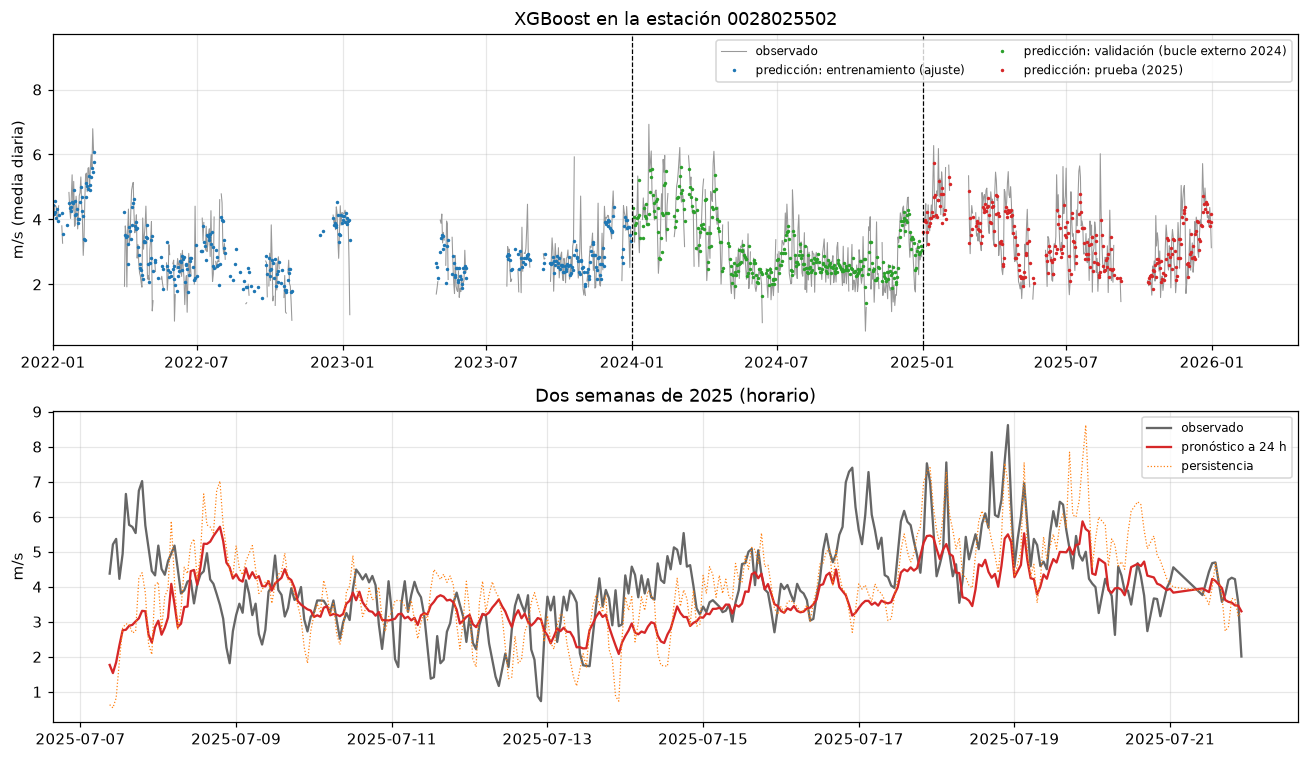

In [22]:
# estación con más datos en los pliegues de validación de 2024 y en 2025
val_idx = np.concatenate([va for _, _, va in EXT])
cuenta = TR.est.iloc[val_idx].value_counts().add(TE.est.value_counts(), fill_value=0)
EST = cuenta.idxmax()
p_val = np.concatenate([leer(MEJOR, elegido[MEJOR], n)[1] for n in PLIEGUES])
serie = pd.concat([
    pd.DataFrame({"t": TR.t_y, "y": y_tr, "p": p_tr, "tramo": "entrenamiento (ajuste)", "est": TR.est}),
    pd.DataFrame({"t": TR.t_y.iloc[val_idx].to_numpy(), "y": y_tr[val_idx], "p": p_val,
                  "tramo": "validación (bucle externo 2024)", "est": TR.est.iloc[val_idx].to_numpy()}),
    pd.DataFrame({"t": TE.t_y, "y": y_te, "p": p_mejor, "tramo": "prueba (2025)", "est": TE.est})])
s = serie[serie.est == EST]
s = s[~((s.tramo == "entrenamiento (ajuste)") & (s.t >= TRIMESTRES[4]))]   # en 2024 se muestra la validación
fig, axs = plt.subplots(2, 1, figsize=(12, 7))
dd = s.groupby(["tramo", s.t.dt.floor("D")])[["y", "p"]].mean().reset_index()
obs = s.groupby(s.t.dt.floor("D")).y.mean().asfreq("D")          # los días sin datos quedan como huecos
axs[0].plot(obs.index, obs, color="0.6", lw=.7, label="observado")
for tr_, c in zip(["entrenamiento (ajuste)", "validación (bucle externo 2024)", "prueba (2025)"], ["C0", "C2", "C3"]):
    d = dd[dd.tramo == tr_]
    axs[0].plot(d.t, d.p, ".", ms=2.5, color=c, label=f"predicción: {tr_}")
axs[0].axvline(TRIMESTRES[4], color="k", ls="--", lw=.8)
axs[0].axvline(pd.Timestamp("2025-01-01"), color="k", ls="--", lw=.8)
axs[0].set(ylabel="m/s (media diaria)", title=f"{MEJOR} en la estación {EST}", xlim=(pd.Timestamp("2022-01-01"), None))
axs[0].legend(fontsize=8, ncol=2)
z = s[(s.tramo == "prueba (2025)")].set_index("t").sort_index()
z = z[z.index >= z.index[len(z) // 2]].iloc[:24 * 14]
axs[1].plot(z.index, z.y, color="0.4", label="observado")
axs[1].plot(z.index, z.p, color="C3", label="pronóstico a 24 h")
axs[1].plot(z.index, TE.set_index(["est", "t_y"]).loc[EST].vel_l0.reindex(z.index), color="C1", lw=.8, ls=":",
            label="persistencia")
axs[1].set(ylabel="m/s", title="Dos semanas de 2025 (horario)")
axs[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

En azul están las predicciones sobre los datos de ajuste (2020–2023), en verde las de los cuatro pliegues
externos de 2024 (cada trimestre pronosticado por un modelo que no lo vio) y en rojo las de 2025. Las tres siguen
igual de bien la media diaria observada, otra señal de que el modelo no memoriza el entrenamiento. En la escala
horaria, el pronóstico es mucho más suave que la persistencia: sigue el ciclo diario y los cambios de régimen de
varios días, pero no anticipa los picos de una o dos horas.

### Diagnóstico de residuos

In [23]:
e_te = y_te - p_mejor
white = ev.prueba_white(e_te, X_te)
ind = ev.pruebas_independencia(TE.est.to_numpy(), TE.t.to_numpy(), e_te)
print(f"White: LM = {white['estadistico_LM']:.1f}, p = {white['p_valor']:.2g}")
print(f"BDS: rechaza independencia (5 %) en {100 * (ind.p_BDS < .05).mean():.0f} % de {len(ind)} estaciones")
print(f"Ljung-Box (24 rezagos): rechaza en {100 * (ind.p_LjungBox < .05).mean():.0f} % de las estaciones")
print(f"Media de los residuos: {e_te.mean():.4f} m/s | asimetría {stats.skew(e_te):.2f} | "
      f"curtosis en exceso {stats.kurtosis(e_te):.2f}")

White: LM = 4016.7, p = 0
BDS: rechaza independencia (5 %) en 100 % de 53 estaciones
Ljung-Box (24 rezagos): rechaza en 100 % de las estaciones
Media de los residuos: 0.0069 m/s | asimetría 0.91 | curtosis en exceso 4.04


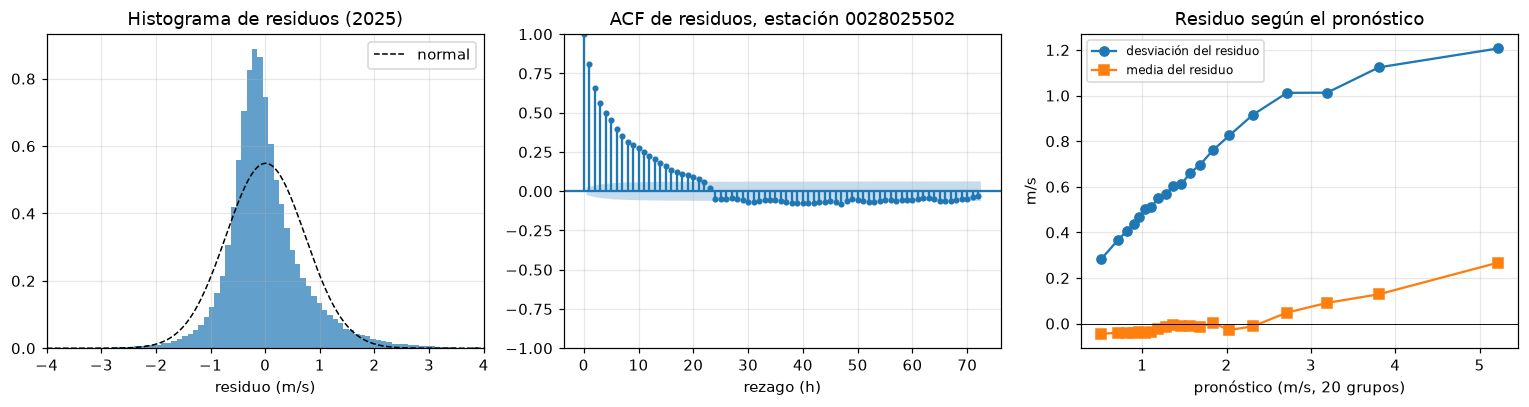

In [24]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
axs[0].hist(e_te, bins=120, density=True, color="C0", alpha=.7)
xx = np.linspace(-4, 4, 200)
axs[0].plot(xx, stats.norm.pdf(xx, e_te.mean(), e_te.std()), "k--", lw=1, label="normal")
axs[0].set(xlabel="residuo (m/s)", title="Histograma de residuos (2025)", xlim=(-4, 4))
axs[0].legend()
r_est = pd.Series(e_te, index=pd.MultiIndex.from_arrays([TE.est, TE.t])).loc[EST].sort_index()
r_est = r_est.reindex(pd.date_range(r_est.index.min(), r_est.index.max(), freq="h"))
plot_acf(r_est.to_numpy(), lags=72, missing="conservative", ax=axs[1], markersize=3)
axs[1].set(title=f"ACF de residuos, estación {EST}", xlabel="rezago (h)")
q = pd.qcut(p_mejor, 20)
g = pd.DataFrame({"p": p_mejor, "e": e_te}).groupby(q, observed=True).agg(p=("p", "mean"), sd=("e", "std"), m=("e", "mean"))
axs[2].plot(g.p, g.sd, "o-", label="desviación del residuo")
axs[2].plot(g.p, g.m, "s-", label="media del residuo")
axs[2].axhline(0, color="k", lw=.6)
axs[2].set(xlabel="pronóstico (m/s, 20 grupos)", ylabel="m/s", title="Residuo según el pronóstico")
axs[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

Los residuos no son ruido blanco. La prueba de White rechaza la homocedasticidad, y el gráfico de la
derecha muestra que la desviación del residuo crece con el pronóstico: el error es mayor cuando se espera más
viento. BDS y Ljung-Box rechazan la independencia en todas las estaciones. La ACF de la estación mostrada
decae despacio durante unas 20 horas: un error grande tiende a repetirse en las horas siguientes, porque los
cambios de régimen que el modelo no anticipa duran varias horas. La distribución tiene
asimetría positiva (`0.91`) y colas pesadas (curtosis en exceso de `4.04`): las ráfagas fuertes se subestiman.
La media del residuo es prácticamente cero (`0.007 m/s`). Este diagnóstico sugiere, para el modelo final, una
pérdida o una transformación que tenga en cuenta la heterocedasticidad y el uso de errores recientes como
predictoras.

## 5.5 Interpretabilidad

### SHAP

Valor base: 1.993 m/s | suma de SHAP + base = predicción: True


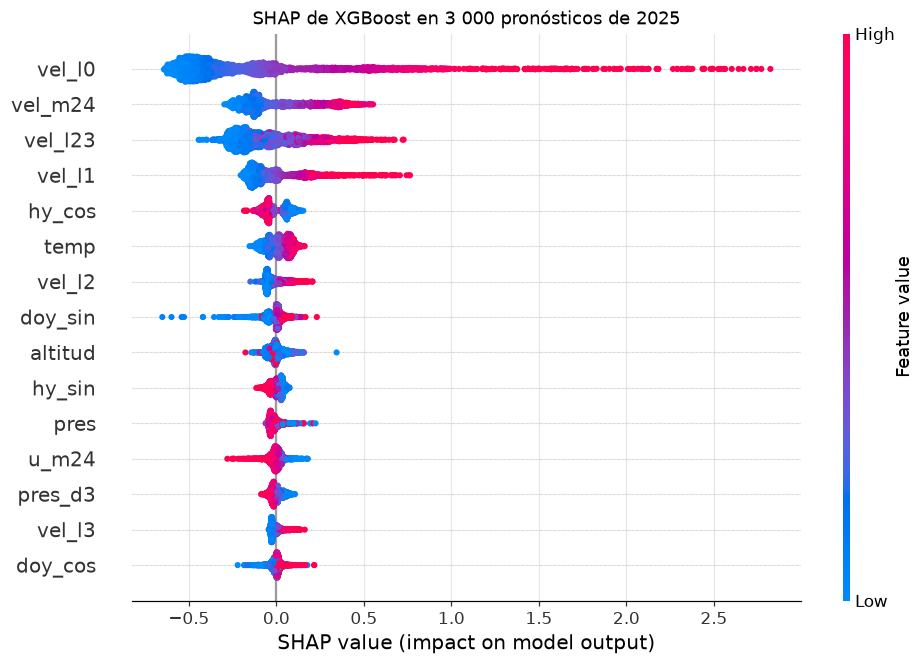

In [25]:
import shap
import xgboost as xgb

idx_shap = submuestra(np.arange(len(TE)), 3000, SEED)
Xs = pd.DataFrame(X_te[idx_shap], columns=F)
booster = modelo.get_booster()
booster.set_param({"device": "cpu"})
contrib = booster.predict(xgb.DMatrix(Xs), pred_contribs=True)       # TreeSHAP exacto; última columna = base
shap_vals, base = contrib[:, :-1], contrib[0, -1]
print(f"Valor base: {base:.3f} m/s | suma de SHAP + base = predicción: "
      f"{np.allclose(shap_vals.sum(1) + base, booster.predict(xgb.DMatrix(Xs)), atol=1e-3)}")
shap.summary_plot(shap_vals, Xs, max_display=15, show=False, plot_size=(9, 6))
plt.title(f"SHAP de {MEJOR} en 3 000 pronósticos de 2025")
plt.show()

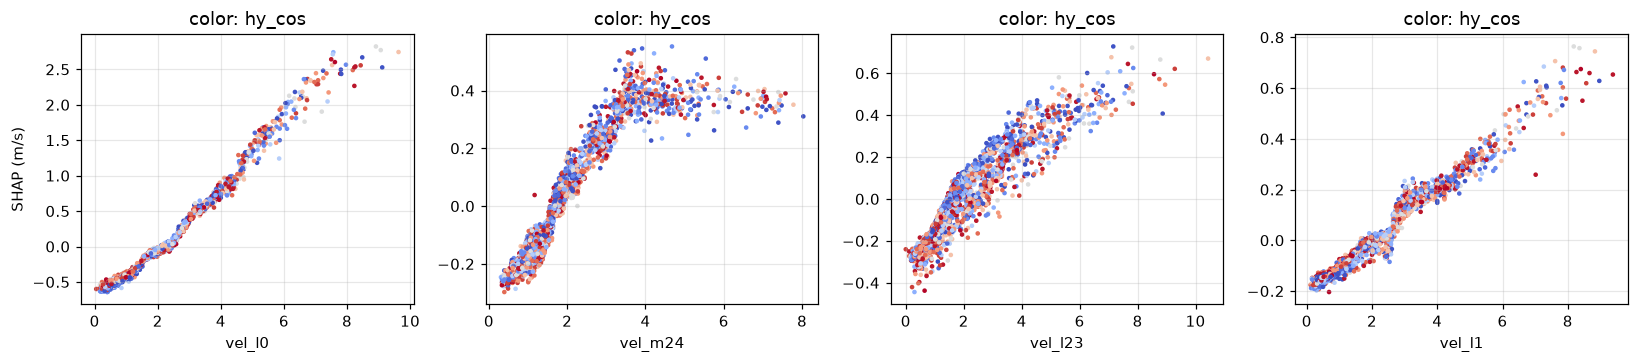

,media |SHAP| (m/s),ganancia (%)
vel_l0,0.452,64.483
vel_m24,0.173,1.904
vel_l23,0.171,5.861
vel_l1,0.122,15.677
hy_cos,0.061,0.871
temp,0.053,0.683
vel_l2,0.046,2.837
doy_sin,0.033,0.425
altitud,0.032,0.450
hy_sin,0.027,0.435


In [26]:
imp = pd.DataFrame({"media |SHAP| (m/s)": np.abs(shap_vals).mean(0),
                    "ganancia (XGBoost)": pd.Series(booster.get_score(importance_type="gain"))
                    .reindex([f"f{i}" for i in range(len(F))]).fillna(0).to_numpy()},
                   index=F)
imp["ganancia (%)"] = 100 * imp["ganancia (XGBoost)"] / imp["ganancia (XGBoost)"].sum()
imp = imp.drop(columns="ganancia (XGBoost)").sort_values("media |SHAP| (m/s)", ascending=False)
top = imp.index[:4]
fig, axs = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, f in zip(axs, top):
    i = F.index(f)
    color_f = "hy_cos" if f != "hy_cos" else "vel_l0"
    sc = ax.scatter(Xs[f], shap_vals[:, i], c=Xs[color_f], s=4, cmap="coolwarm")
    ax.set(xlabel=f, ylabel="SHAP (m/s)" if f == top[0] else "", title=f"color: {color_f}")
plt.tight_layout()
plt.show()
imp.head(12).round(3)

Calculamos los valores SHAP con TreeSHAP exacto sobre 3 000 pronósticos de 2025; la suma de los valores SHAP
y el valor base reproduce cada predicción. La velocidad actual (`vel_l0`) domina (`0.45 m/s` de contribución
media absoluta), seguida de la media de las últimas 24 h (`vel_m24`) y de la velocidad de hace 23 h (`vel_l23`),
que es la misma hora del día del objetivo. Después aparecen la hora del día (`hy_cos`) y la temperatura. Las
gráficas de dependencia muestran que el efecto de `vel_l0` y de `vel_l1` es casi lineal, mientras que el de la
media de 24 h se satura por encima de unos 4 m/s y el de `vel_l23` se curva: son las no linealidades que un modelo
lineal no captura, aunque su peso en el error total es pequeño. La importancia por ganancia de XGBoost concentra
el `64 %` en `vel_l0` y el `16 %` en `vel_l1`, y casi ignora `vel_m24` (`2 %`). Como los rezagos están muy
correlacionados, la ganancia se la lleva la variable que el árbol usa primero; SHAP reparte mejor el crédito
entre variables redundantes.

### LIME

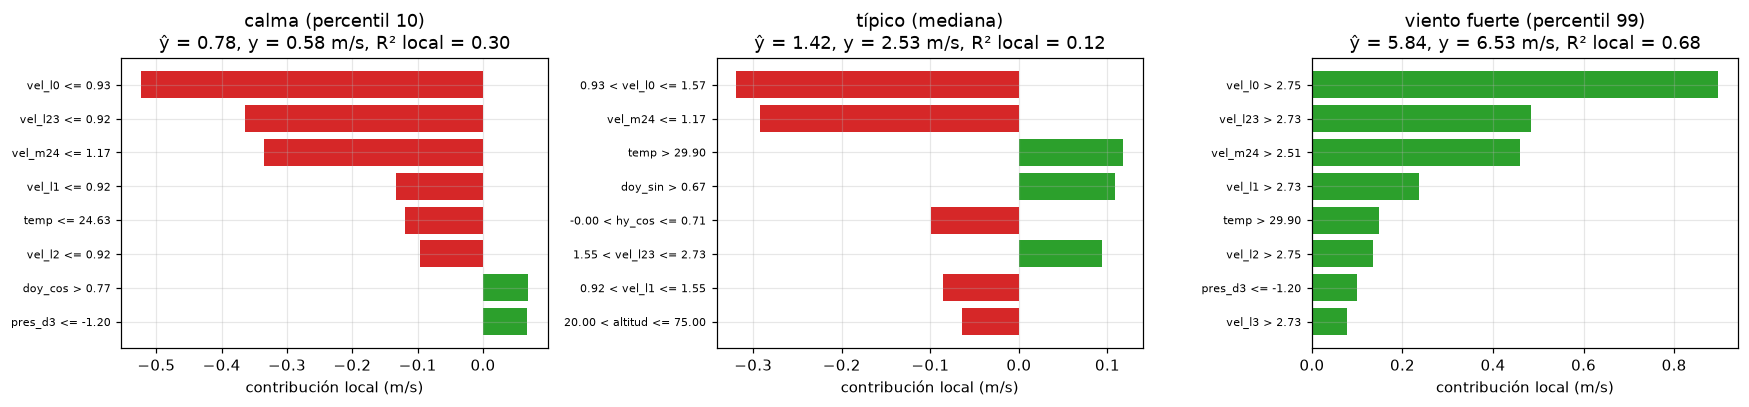

In [27]:
from lime.lime_tabular import LimeTabularExplainer

ref = submuestra(np.arange(len(TR)), 20000, SEED)
explicador = LimeTabularExplainer(X_tr[ref], feature_names=F, mode="regression", discretize_continuous=True,
                                  random_state=SEED)
casos = {"calma (percentil 10)": np.quantile(p_mejor, .1), "típico (mediana)": np.quantile(p_mejor, .5),
         "viento fuerte (percentil 99)": np.quantile(p_mejor, .99)}
fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (nombre, q_) in zip(axs, casos.items()):
    i = int(np.argmin(np.abs(p_mejor - q_)))
    exp = explicador.explain_instance(X_te[i], lambda Z: modelo.predict(Z.astype(np.float32)), num_features=8,
                                      num_samples=3000)
    lst = exp.as_list()[::-1]
    ax.barh([a for a, _ in lst], [b for _, b in lst], color=["C3" if b < 0 else "C2" for _, b in lst])
    ax.set(title=f"{nombre}\nŷ = {p_mejor[i]:.2f}, y = {y_te[i]:.2f} m/s, R² local = {exp.score:.2f}",
           xlabel="contribución local (m/s)")
    ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.show()

LIME ajusta un modelo lineal local alrededor de cada pronóstico. En los tres casos, las condiciones sobre la
velocidad actual, la de hace 23 h y la media de 24 h son las que más contribuyen, con el mismo signo que en SHAP.
En calma, las velocidades bajas de todas las horas previas empujan el pronóstico hacia abajo; en el caso típico,
la temperatura alta y la época del año lo compensan en parte; con viento fuerte, las velocidades altas lo empujan
hacia arriba en casi `0.9 m/s`. El `R²` local indica qué tan bien la aproximación lineal describe al modelo cerca
de ese punto: es alto con viento fuerte (`0.68`) y bajo en el caso típico (`0.12`), donde la explicación local es
solo orientativa.

## 5.6 Robustez y sobreajuste

### Curva de aprendizaje

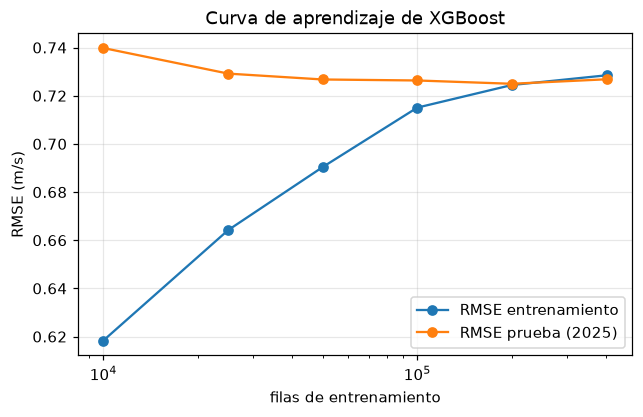

,RMSE entrenamiento,RMSE prueba (2025)
n,,
10000,0.6183,0.7398
25000,0.6642,0.7292
50000,0.6904,0.7267
100000,0.7151,0.7263
200000,0.7244,0.7250
402200,0.7285,0.7268


In [28]:
filas = []
for n in [10000, 25000, 50000, 100000, 200000, len(TR)]:
    idx = submuestra(np.arange(len(TR)), n, SEED)
    m_ = ajustar_mejor(X_tr[idx], y_tr[idx])
    filas.append({"n": n, "RMSE entrenamiento": np.sqrt(np.mean((y_tr[idx] - m_.predict(X_tr[idx])) ** 2)),
                  "RMSE prueba (2025)": np.sqrt(np.mean((y_te - m_.predict(X_te)) ** 2))})
curva = pd.DataFrame(filas).set_index("n")
ax = curva.plot(marker="o", logx=True, figsize=(6.5, 3.8), title=f"Curva de aprendizaje de {MEJOR}")
ax.set(xlabel="filas de entrenamiento", ylabel="RMSE (m/s)")
plt.show()
curva.round(4)

La curva de aprendizaje confirma que el modelo no sobreajusta. Con pocas filas, el error de entrenamiento
es menor que el de prueba, y la brecha se cierra al crecer la muestra: con 200 mil filas los dos errores coinciden
(`0.724` y `0.725`). Por encima de 100 mil filas el error de prueba ya no mejora, así que más datos de las mismas
estaciones no ayudarían. Para bajar el error hacen falta predictoras con información nueva, no más filas.

### Prueba de permutación de la respuesta

In [29]:
rng = np.random.default_rng(SEED)
idx_a = submuestra(np.arange(len(TR)), 40000, SEED)
idx_b = submuestra(np.arange(len(TE)), 20000, SEED)


def rmse_sub(y_aj):
    m_ = ajustar_mejor(X_tr[idx_a], y_aj)
    return np.sqrt(np.mean((y_te[idx_b] - m_.predict(X_te[idx_b])) ** 2))


real = rmse_sub(y_tr[idx_a])
nulos = np.array([rmse_sub(rng.permutation(y_tr[idx_a])) for _ in range(49)])
p_perm = (1 + (nulos <= real).sum()) / (len(nulos) + 1)
print(f"RMSE con la respuesta real: {real:.4f} | con la respuesta permutada: {nulos.mean():.4f} ± {nulos.std():.4f} "
      f"(mín. {nulos.min():.4f}) | p = {p_perm:.2f} con 49 permutaciones")

RMSE con la respuesta real: 0.7320 | con la respuesta permutada: 1.4450 ± 0.0096 (mín. 1.4235) | p = 0.02 con 49 permutaciones


En la prueba de permutación ajustamos el modelo con la respuesta desordenada al azar, lo que rompe toda
relación entre predictoras y objetivo. Con la respuesta real el RMSE es `0.732`; con la permutada, `1.445 ±
0.010`, y ninguna de las 49 permutaciones se acerca. El p-valor es el mínimo posible con 49 permutaciones
(`0.02`). El modelo aprende una relación real y no un artefacto del procedimiento.

## 5.7 Comparación estadística de los modelos

### Friedman y Nemenyi con bloques estación × trimestre

Friedman: χ² = 126.2, gl = 6, p = 8.2e-25, N = 76 bloques (estación × trimestre con ≥ 48 horas), CD = 1.03


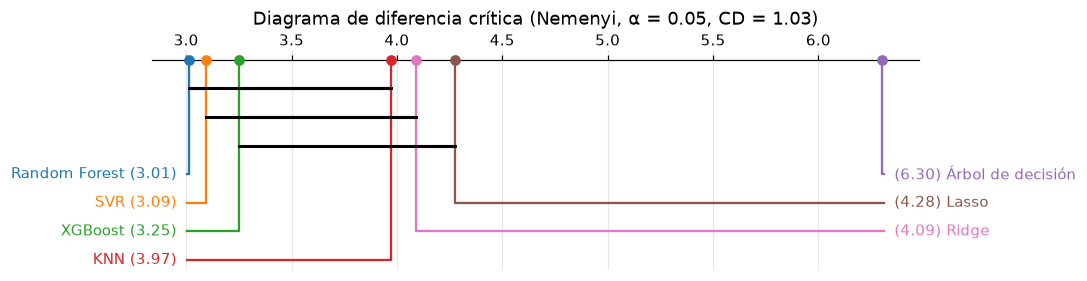

,XGBoost,Random Forest,SVR,Ridge,Lasso,KNN,Árbol de decisión
XGBoost,1.000,0.994,0.999,0.197,0.053,0.374,0.0
Random Forest,0.994,1.000,1.000,0.034,0.006,0.088,0.0
SVR,0.999,1.000,1.000,0.065,0.013,0.154,0.0
Ridge,0.197,0.034,0.065,1.000,0.998,1.000,0.0
Lasso,0.053,0.006,0.013,0.998,1.000,0.978,0.0
KNN,0.374,0.088,0.154,1.000,0.978,1.000,0.0
Árbol de decisión,0.000,0.000,0.000,0.000,0.000,0.000,1.0


In [30]:
bloques = []
for k, (n, tr, va) in enumerate(EXT):
    d = pd.DataFrame({"est": TR.est.iloc[va].to_numpy(), "y": y_tr[va]})
    for m in orden_modelos:
        d[m] = (d.y - leer(m, elegido[m], n)[1]) ** 2
    g = d.groupby("est")
    b = np.sqrt(g[list(orden_modelos)].mean())[g.size() >= 48]
    b.index = [f"{e} · {n}" for e in b.index]
    bloques.append(b)
bloques = pd.concat(bloques)
fr = ev.friedman_nemenyi(bloques)
print(f"Friedman: χ² = {fr['chi2']:.1f}, gl = {fr['gl']}, p = {fr['p_valor']:.2g}, N = {fr['N']} bloques "
      f"(estación × trimestre con ≥ 48 horas), CD = {fr['CD']:.2f}")
fig, ax = plt.subplots(figsize=(9, 2.6))
sp.critical_difference_diagram(fr["rangos"], fr["nemenyi"], ax=ax, label_fmt_left="{label} ({rank:.2f})  ",
                               label_fmt_right="  ({rank:.2f}) {label}")
ax.set_title(f"Diagrama de diferencia crítica (Nemenyi, α = 0.05, CD = {fr['CD']:.2f})")
plt.show()
fr["nemenyi"].round(3)

Para comparar los modelos en validación usamos como bloques cada estación en cada trimestre de 2024 (76
bloques con al menos 48 horas), que son unidades independientes del ajuste. Friedman rechaza que los siete
modelos sean equivalentes (`χ² = 126.2`, `p < 10⁻²⁴`). El diagrama de diferencia crítica agrupa con una barra a los
modelos cuyos rangos no difieren según Nemenyi (`CD = 1.03`). Random Forest, SVR y XGBoost forman el grupo líder y
no se distinguen entre sí. Random Forest es significativamente mejor que Ridge y Lasso, y el árbol de decisión es
peor que todos.

### *Model Confidence Set* en 2025

In [31]:
preds_cmp = dict(pred_te) | {"Persistencia (24 h)": pers_te}
L = ev.perdida_diaria(TE.t, y_te, preds_cmp)
print(f"{len(L)} días de 2025")
ev.mcs(L).round(4)

311 días de 2025


,p_MCS,en el conjunto,pérdida media
Model name,,,
Random Forest,1.0000,True,0.5696
XGBoost,0.0940,False,0.5746
SVR,0.0855,False,0.5782
Ridge,0.0735,False,0.5825
Lasso,0.0735,False,0.5825
KNN,0.0000,False,0.5886
Árbol de decisión,0.0000,False,0.6307
Persistencia (24 h),0.0000,False,0.7672


El *Model Confidence Set* con `α = 0.10` (bootstrap estacionario con bloques de 7 días sobre las pérdidas
diarias de 2025) conserva solo a Random Forest. XGBoost queda justo fuera (`p = 0.094`), igual que SVR, Ridge y
Lasso (`p ≈ 0.07–0.09`); KNN, el árbol y la persistencia se descartan con `p = 0`. Como el umbral está muy cerca,
lo prudente es decir que Random Forest es el mejor y que XGBoost, SVR y los lineales están cerca del límite.

### Giacomini-White, Clark-West y Diebold-Mariano

In [32]:
filas = []
for m in orden_modelos[1:]:
    d = L[MEJOR] - L[m]
    dm = ev.diebold_mariano(L[MEJOR], L[m])
    gw = ev.giacomini_white(L[MEJOR], L[m])
    lo, hi = ev.ic_bootstrap_estacionario(d)
    cl = ev.delta_cliff(L[MEJOR], L[m])
    filas.append({"rival": m, "dif. media de pérdida": d.mean(), "IC 95 % (bootstrap estacionario)": f"{lo:.4f} – {hi:.4f}",
                  "DM-HLN": dm["DM_HLN"], "p DM": dm["p_valor"], "GW": gw["GW"], "p GW": gw["p_valor"],
                  "δ de Cliff": cl, "magnitud": ev.magnitud_cliff(cl), "d de Cohen": ev.d_cohen(L[MEJOR], L[m])})
cmp = pd.DataFrame(filas).set_index("rival")
cmp["p DM (Holm)"] = multipletests(cmp["p DM"], method="holm")[1]
cmp["p GW (Holm)"] = multipletests(cmp["p GW"], method="holm")[1]
print(f"Comparaciones de {MEJOR} (A) contra cada rival (B): pérdida diaria A − B; negativo favorece a {MEJOR}")
cmp.round(4)

Comparaciones de XGBoost (A) contra cada rival (B): pérdida diaria A − B; negativo favorece a XGBoost


,dif. media de pérdida,IC 95 % (bootstrap estacionario),DM-HLN,p DM,GW,p GW,δ de Cliff,magnitud,d de Cohen,p DM (Holm),p GW (Holm)
rival,,,,,,,,,,,
Random Forest,0.0050,-0.0006 – 0.0113,1.5994,0.1107,3.7251,0.1553,0.0129,despreciable,0.0934,0.4430,0.1553
SVR,-0.0036,-0.0108 – 0.0064,-0.8796,0.3797,7.0168,0.0299,-0.0273,despreciable,-0.0582,0.5170,0.0599
Ridge,-0.0079,-0.0200 – 0.0055,-1.3678,0.1724,10.4774,0.0053,-0.0277,despreciable,-0.0909,0.5170,0.0211
Lasso,-0.0079,-0.0200 – 0.0055,-1.3679,0.1723,10.4854,0.0053,-0.0277,despreciable,-0.0909,0.5170,0.0211
KNN,-0.0140,-0.0229 – -0.0059,-3.3650,0.0009,12.6978,0.0017,-0.0339,despreciable,-0.2009,0.0043,0.0087
Árbol de decisión,-0.0560,-0.0713 – -0.0450,-11.4738,0.0000,287.9637,0.0000,-0.1595,pequeño,-0.8084,0.0000,0.0000


Comparamos el modelo elegido, XGBoost, con cada rival usando las pérdidas cuadráticas diarias de 2025:

- **Diebold-Mariano con la corrección de Harvey, Leybourne y Newbold:** pregunta si la pérdida esperada es
  igual. Tras corregir por Holm, XGBoost solo es significativamente mejor que KNN y que el árbol. Frente a
  Random Forest la diferencia (`+0.005`, a favor de Random Forest) no es significativa (`p = 0.44`), y el
  intervalo del bootstrap estacionario incluye el cero.
- **Giacomini-White:** pregunta si la diferencia de pérdidas es predecible con lo ocurrido el día anterior.
  Rechaza también frente a Ridge y Lasso (`p = 0.021` con Holm): XGBoost no es mejor en promedio, pero sí en
  ciertos días, en particular después de días con errores grandes.
- **Tamaño del efecto:** salvo frente al árbol (`δ` de Cliff pequeño, `d = −0.81`), todas las diferencias son
  despreciables. Aunque algunas sean significativas con 311 días, su magnitud práctica es pequeña.

In [33]:
# Clark-West: la persistencia está anidada en todos los modelos (vel(t) es una de sus predictoras)
dp = ev.perdida_diaria(TE.t, pers_te, pred_te)       # media diaria de (persistencia − pronóstico)²
cw = pd.DataFrame({m: ev.clark_west(L["Persistencia (24 h)"], L[m], dp[m]) for m in orden_modelos}).T
cw["p (Holm)"] = multipletests(cw.p_valor, method="holm")[1]
cw.round(4)

,CW,p_valor,p (Holm)
XGBoost,30.3194,0.0,0.0
Random Forest,27.2458,0.0,0.0
SVR,30.8077,0.0,0.0
Ridge,29.3851,0.0,0.0
Lasso,29.3858,0.0,0.0
KNN,27.1377,0.0,0.0
Árbol de decisión,33.9766,0.0,0.0


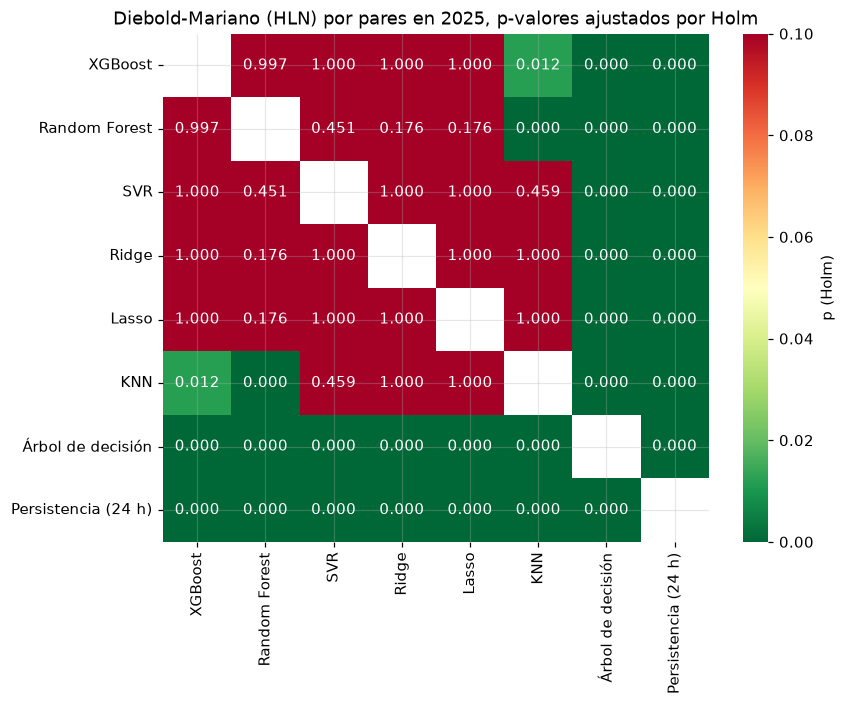

In [34]:
# misma comparación por pares para todos los modelos (DM-HLN con Holm sobre las 28 parejas)
mods = list(orden_modelos) + ["Persistencia (24 h)"]
pares = [(a, b) for i, a in enumerate(mods) for b in mods[i + 1:]]
pv = multipletests([ev.diebold_mariano(L[a], L[b])["p_valor"] for a, b in pares], method="holm")[1]
M = pd.DataFrame(np.nan, mods, mods)
for (a, b), p in zip(pares, pv):
    M.loc[a, b] = M.loc[b, a] = p
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(M, annot=True, fmt=".3f", cmap="RdYlGn_r", vmin=0, vmax=.1, ax=ax, cbar_kws={"label": "p (Holm)"})
ax.set_title("Diebold-Mariano (HLN) por pares en 2025, p-valores ajustados por Holm")
plt.show()

Clark-West es la prueba adecuada cuando un modelo está anidado en otro: la persistencia es un caso
particular de todos los modelos, porque `vel(t)` es una de sus predictoras. La prueba corrige el sesgo que
tendría Diebold-Mariano en ese caso y rechaza con holgura en los siete modelos (`p ≈ 0`). El mapa de calor resume
las 28 comparaciones por pares con Diebold-Mariano y Holm: los cinco mejores modelos no se distinguen entre sí, y
todos difieren de la persistencia y del árbol.

## 5.8 Tabla maestra

In [35]:
maestra = T.groupby(["modelo", "optimizador"]).apply(lambda d: pd.Series({
    "RMSE externo": f"{d[d.pliegue != 'final'].rmse.mean():.4f} ± {d[d.pliegue != 'final'].rmse.std():.4f}"
    if (d.pliegue != "final").any() else "—",
    "MAE externo": d[d.pliegue != "final"].mae.mean(),
    "RMSE interno (final)": d[d.pliegue == "final"].mejor_rmse_interno.iloc[0],
    "RMSE 2025": d[d.pliegue == "final"].rmse.iloc[0], "MAE 2025": d[d.pliegue == "final"].mae.iloc[0],
    "R² 2025": d[d.pliegue == "final"].r2.iloc[0],
    "evaluaciones": d.evaluaciones.iloc[0] if d.evaluaciones.notna().any() else 9,
    "minutos de búsqueda": d.segundos_busqueda.sum() / 60,
    "configuración final": json.dumps(d[d.pliegue == "final"].mejor_params.iloc[0], ensure_ascii=False)}))
maestra["elegido"] = [o == elegido.get(m) for m, o in maestra.index]
maestra = maestra.loc[[i for m in orden_modelos for i in maestra.index if i[0] == m]]
maestra.to_csv(RESULTADOS / "tabla_maestra_resumen.csv")
maestra.round(4)

RMSE externo  MAE externo  \
modelo            optimizador                                          
XGBoost           Aleatoria             0.8950 ± 0.0932       0.6388   
                  Bayesiana (Optuna)    0.8976 ± 0.0940       0.6406   
                  Eliminación sucesiva                —          NaN   
                  Genética (DEAP)       0.8983 ± 0.0946       0.6418   
                  Rejilla               0.8956 ± 0.0962       0.6395   
Random Forest     Aleatoria             0.8971 ± 0.0945       0.6398   
                  Bayesiana (Optuna)    0.8961 ± 0.0931       0.6393   
                  Eliminación sucesiva                —          NaN   
                  Genética (DEAP)       0.8974 ± 0.0951       0.6400   
                  Rejilla               0.8961 ± 0.0934       0.6399   
SVR               Aleatoria             0.9083 ± 0.0932       0.6493   
                  Bayesiana (Optuna)    0.9113 ± 0.0967       0.6463   
                  Genética (DEAP)       0.9006 ± 0.0935       0.6429   
                  Rejilla               0.8999 ± 0.0944       0.6412   
Ridge             Aleatoria             0.9103 ± 0.0967       0.6484   
                  Bayesiana (Optuna)    0.9103 ± 0.0967       0.6484   
                  Genética (DEAP)       0.9103 ± 0.0967       0.6484   
                  Rejilla               0.9103 ± 0.0967       0.6484   
Lasso             Aleatoria             0.9103 ± 0.0967       0.6484   
                  Bayesiana (Optuna)    0.9104 ± 0.0967       0.6484   
                  Genética (DEAP)       0.9104 ± 0.0967       0.6484   
                  Rejilla               0.9104 ± 0.0967       0.6484   
KNN               Aleatoria             0.9239 ± 0.0985       0.6454   
                  Bayesiana (Optuna)    0.9229 ± 0.0980       0.6448   
                  Genética (DEAP)       0.9238 ± 0.0981       0.6455   
                  Rejilla               0.9223 ± 0.0977       0.6446   
Árbol de decisión Aleatoria             0.9343 ± 0.0978       0.6659   
                  Bayesiana (Optuna)    0.9402 ± 0.0963       0.6712   
                  Genética (DEAP)       0.9348 ± 0.0984       0.6670   
                  Rejilla               0.9407 ± 0.0950       0.6712   

                                        RMSE interno (final)  RMSE 2025  \
modelo            optimizador                                             
XGBoost           Aleatoria                           0.8976     0.7268   
                  Bayesiana (Optuna)                  0.8965     0.7244   
                  Eliminación sucesiva                0.8997     0.7295   
                  Genética (DEAP)                     0.8978     0.7272   
                  Rejilla                             0.8968     0.7231   
Random Forest     Aleatoria                           0.9020     0.7236   
                  Bayesiana (Optuna)                  0.8994     0.7227   
                  Eliminación sucesiva                0.9035     0.7243   
                  Genética (DEAP)                     0.9002     0.7235   
                  Rejilla                             0.8998     0.7228   
SVR               Aleatoria                           0.9036     0.7350   
                  Bayesiana (Optuna)                  0.9037     0.7334   
                  Genética (DEAP)                     0.8967     0.7311   
                  Rejilla                             0.8960     0.7311   
Ridge             Aleatoria                           0.9040     0.7330   
                  Bayesiana (Optuna)                  0.9040     0.7330   
                  Genética (DEAP)                     0.9040     0.7330   
                  Rejilla                             0.9040     0.7330   
Lasso             Aleatoria                           0.9041     0.7330   
                  Bayesiana (Optuna)                  0.9041     0.7330   
                  Genética (DEAP)                     0.9041     0.7330   
             

La tabla maestra reúne, para cada combinación de modelo y optimizador, el RMSE del bucle externo (media ±
desviación), el RMSE interno de la búsqueda final, las métricas en 2025, el número de evaluaciones, el tiempo total
de búsqueda y la configuración final. La columna `elegido` marca el optimizador que seleccionó el bucle externo. La
tabla se guarda en `resultados/e3/tabla_maestra_resumen.csv`, y la versión por tarea (una fila por búsqueda) en
`resultados/e3/tabla_maestra.csv`.

## 5.9 Conclusiones

1. Con validación anidada temporal y el mismo presupuesto de 40 evaluaciones, los cuatro optimizadores
   llegan a configuraciones de calidad equivalente (Friedman `p = 0.69`). La variabilidad entre trimestres y la
   debida a la semilla del optimizador son mayores que las diferencias entre estrategias. El algoritmo genético
   resultó el más barato en XGBoost porque converge hacia configuraciones más livianas, y la optimización
   bayesiana fue la más estable entre semillas.
2. La eliminación sucesiva no mejoró a la búsqueda aleatoria con el mismo costo: con 1/9 de las filas el orden
   de las configuraciones no se mantiene con todos los datos.
3. Los tiempos medidos siguen la complejidad teórica (exponentes cercanos a 1 en los modelos lineales y a
   `n log n` en los árboles; cuadrático en el SVR con núcleo completo). Las mayores ganancias computacionales vienen
   de elegir bien el algoritmo: búsqueda exhaustiva en KNN, Cholesky en Ridge, histogramas en XGBoost, Nyström en
   el SVR con núcleo RBF y parada temprana.
4. El bucle externo eligió XGBoost con búsqueda aleatoria (`RMSE = 0.7268` en 2025); Random Forest fue el mejor en
   2025 (`0.7227`) y el único en el MCS al `10 %`, pero la diferencia entre ambos no es significativa según
   Diebold-Mariano y su tamaño de efecto es despreciable. Los dos mejoran al SVR lineal del capítulo anterior
   (`0.733`) y reducen el error de la persistencia en un `14 %`.
5. El modelo no sobreajusta (errores de entrenamiento y prueba iguales, curva de aprendizaje convergida, prueba
   de permutación con `p = 0.02`). Pero sus residuos son heterocedásticos y conservan dependencia temporal, y
   SHAP muestra que casi toda la información viene de la velocidad reciente. Para el modelo final, lo que puede
   mejorar el pronóstico no es otro algoritmo con las mismas predictoras, sino información nueva sobre el estado
   de la atmósfera.

**Limitaciones.** El presupuesto de 40 evaluaciones y las submuestras de 40 mil filas abaratan la búsqueda, pero
pueden favorecer configuraciones que funcionan bien con pocos datos. Los trimestres de 2024 tienen entre 7 y 38
estaciones, lo que hace variable el RMSE externo. Los tiempos de las búsquedas son de reloj con varios procesos
compartiendo la máquina, por lo que solo son comparables dentro de un mismo modelo; las mediciones de la
sección 5.3 se hicieron con la máquina dedicada.

In [36]:
import importlib.metadata as md
print("Versiones:", {p: md.version(p) for p in ["numpy", "pandas", "scikit-learn", "xgboost", "optuna", "deap",
                                                 "shap", "lime", "arch", "scikit-posthocs", "statsmodels", "scipy"]},
      "| semilla:", SEED)

Versiones: {'numpy': '2.4.6', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'xgboost': '3.2.0', 'optuna': '5.0.0', 'deap': '1.4.4', 'shap': '0.51.0', 'lime': '0.2.0.1', 'arch': '8.0.0', 'scikit-posthocs': '0.17.1', 'statsmodels': '0.15.0', 'scipy': '1.17.1'} | semilla: 42
